# Applying Connectome Spectrum Electromagnetic Tomography (CSET) on individual data

CSET solves the following optimization problem: 
$$\hat {\mathbf s}^* = \underset{\hat{\mathbf s}}{\text{argmin}} \lVert \mathbf{LU}\hat{\mathbf s}-\mathbf{y} \rVert_2^2 + \lambda \lVert \hat{\mathbf s}\rVert_1$$
$$ \mathbf s^* = \mathbf U \hat{\mathbf s}$$

where
- $\mathbf{s}^* \in \mathbb{R}^n$ are the reconstructed dipole strengths
- $\hat{\mathbf{s}}^* \in \mathbb{R}^n$ is the reconstructed connectome spectrum.
- $\mathbf{y} \in \mathbb{R}^m$ are the EEG measurements.
- $\mathbf L \in \mathbb{R}^{m\times n}$ is the lead field matrix.
- $\mathbf U \in \mathbb{R}^{n \times n}$ is the inverse graph Fourier transform
- $\lambda \in \mathbb{R}$ is the regularizer parameter.

Regularizing with $\lVert \hat {\mathbf s}\rVert_1$ imposes the connectome spectrum to be sparse.

# Batch Wise Run
Run the code for all subjects of a given dataset.

## 📦 Imports

In [1]:
import mindmap as mm
from pathlib import Path

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- Configuration file (`config`)
- `subjects`: list of subjects to process
- `samples`: list of samples to process


🎚️ **<font color=pink>Parameters</font>**
- Regularizer parameter (`lam`)
- Depth Weighting scale (`dw`)
- Window size (`win_size`): time window around EEG peak in [s]
- Scale (`scale`)

In [ ]:
# config
config   = mm.io.read_config("../configurations/spike.yml")
subjects = config["SUBS"]
samples  = config["SAMP"]
mm_dir   = Path(config["MM_DIR"])

# options
overwrite = True

# parameters
win_size = 0.01 
lam      = 1 
dw       = 1/2

# file naming
fstc = lambda sub, samp: mm_dir/sub/"inv"/f"{sub}_{samp}_cset-{lam}"

## ♾️ Loop

In [3]:
for sub in subjects:
    for samp in samples:

        # check file existence
        stc_fname = fstc(sub, samp)
        exists = mm.utils.files_exists(stc_fname, mkdir=True)
        if exists and not overwrite:
            print(f"File to generate already exists for subject '{sub}' and sample '{samp}'")
            continue

        try: 
            data = mm.io.read_dataset(sub, "eeg_inv", "fwd", "cst", sample=samp)
            stc  = mm.cset(data["eeg_inv"], data["fwd"], data["cst"], lam, dw, win_size, sub)
        except Exception as e:
            print(f"\033[91mFailed to compute inverse solution for subject '{sub}', sample '{samp}' due to {e}\033[0m")
            continue
            
        # save
        stc.save(stc_fname, overwrite=True, verbose="warning")
        print(f"\033[92mSuccessfully computed CSET inverse solution for subject '{sub}', sample '{samp}'\033[0m")

Failed to compute inverse solution for subject 'sub-pat01', sample 'spike' due to File does not exist: "/media/nino/DATA/SPIKE/derivatives/mindmap/sub-pat01/fwd/sub-pat01_fwd.fif"
DATA SUMMARY
Dataset: spike
Subject: sub-pat02
Retrieved objects:
- fwd
- eeg_inv
- cst
Missing objects:
Successfully computed CSET inverse solution for subject 'sub-pat02', sample 'spike'
DATA SUMMARY
Dataset: spike
Subject: sub-pat03
Retrieved objects:
- fwd
- eeg_inv
- cst
Missing objects:
Successfully computed CSET inverse solution for subject 'sub-pat03', sample 'spike'
DATA SUMMARY
Dataset: spike
Subject: sub-pat04
Retrieved objects:
- fwd
- eeg_inv
- cst
Missing objects:
Successfully computed CSET inverse solution for subject 'sub-pat04', sample 'spike'
DATA SUMMARY
Dataset: spike
Subject: sub-pat05
Retrieved objects:
- fwd
- eeg_inv
- cst
Missing objects:
Successfully computed CSET inverse solution for subject 'sub-pat05', sample 'spike'
DATA SUMMARY
Dataset: spike
Subject: sub-pat06
Retrieved objects

# Step Wise Run

Run the code step by step for a single subject.

## 📦 Imports

In [1]:
import mindmap as mm
import mne
import numpy as np
from pathlib import Path

import pyxu.abc as pxa
import pyxu.operator as pxo
import pyxu.opt.stop as pxst
from pyxu.opt.solver import PGD

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- Forward solution (`fwd`): lead field matrix for inversion
- Connectome spectrum transform (`cst`): transform for component base
- EEG (`eeg_inv`): data to inverse
- Ground truth (`gt` - optional): To compare

In [11]:
# configuration
config = mm.io.read_config("../configurations/simf.yml")
sub    = config["SUBS"][0]
sample = config["SAMP"][0]

# data
data = mm.io.read_dataset(sub, "fwd", "cst", "eeg_inv", "gt", "resec", sample=sample)

# extract fixed orientation lead field matrix
fwd = mne.convert_forward_solution(data["fwd"], force_fixed=True, verbose="warning")
fwd = fwd["sol"]["data"].astype("float64")                                           

# extract 50% rising phase and peak phase of EEG
sfreq = data["eeg_inv"].info["sfreq"]

_, ht = mm.utils.eeg_rising_phase(data["eeg_inv"], ratio=0.5)
_, pt = mm.utils.eeg_rising_phase(data["eeg_inv"], ratio=1)

t_half = ht/sfreq 
t_peak = pt/sfreq

print(f"50% rising phase time: {t_half:03} [s]")
print(f"Peak phase time: {t_peak:03} [s]")

DATA SUMMARY
Dataset: simf
Subject: vepcon_sub-10
Retrieved objects:
- eeg_inv
- gt
- fwd
- cst
Missing objects:
- resec
50% rising phase time: 0.508 [s]
Peak phase time: 0.552 [s]


## Ground Truth

### 🌟 Visualize ground truth brain signal

In [12]:
if "gt" in data.keys():
    mm.viz.plot_brain_time_series(data["fwd"]["src"], data["gt"].data, sfreq=sfreq)

else:
    plotter = mm.viz.plot_resection(data["fwd"]["src"], data["resec"], color="red")
    plotter.add_legend(face="circle")
    plotter.show()

Widget(value='<iframe src="http://localhost:34397/index.html?ui=P_0x792f01309880_10&reconnect=auto" class="pyv…

#### 🌟 Visualize ground truth spectrum

In [13]:
if "gt" in data.keys():
    mm.viz.plot_spectrum(data["cst"]@data["gt"].data[:,ht]).show()

## EEG

#### 🌟 Visualize EEG topographic maps at 50% rising phase

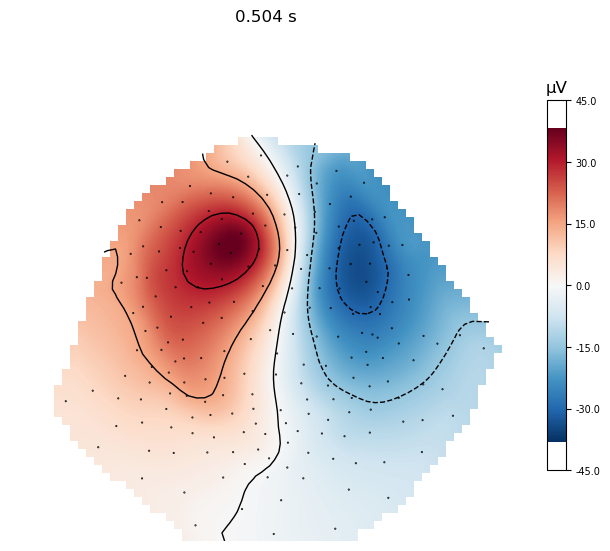

In [29]:
times = [t_half]
_ = data["eeg_inv"].plot_topomap(times=times, size=4, extrapolate="local", outlines=None)

## Select Time points

🛠️ <font color=violet>**Select a time window to reconstruct**</font>: One time sample takes around 1 second to reconstruct. <br>
🎚️ **<font color=pink>Parameters</font>**
- Window size (`win_size`): time window around EEG peak in [s]

Number of samples: 24


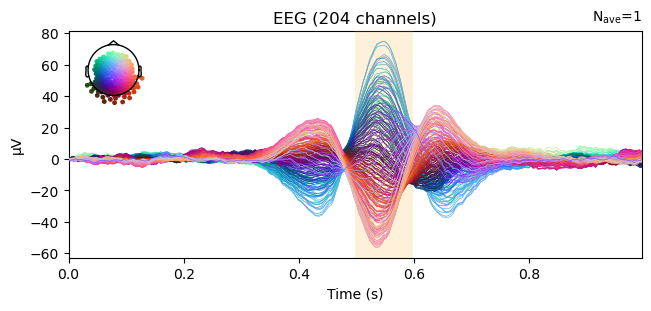

In [30]:
win_size = 0.1      # window size in [s], if None take the 50% rising phase and peak phase only

if win_size is not None:
    dt = int(win_size * sfreq /2)
    Y_  = data["eeg_inv"].data[:, pt-dt:pt+dt]

    t_start  = t_peak-(win_size/2)
    t_end    = t_peak+(win_size/2)
    idx_half = int((t_half-t_start)*sfreq)
    idx_peak = int((t_peak-t_start)*sfreq)

    highlight = [t_start, t_end]

else:
    Y_ = data["eeg_inv"].data[:, [ht,pt]]

    idx_half = 0
    idx_peak = 1

    highlight = [t_half-1e-3, t_half+1e-3], [t_peak-1e-3, t_peak+1e-3]

print(f"Number of samples: {Y_.shape[1]}")
_ = data["eeg_inv"].plot(highlight=highlight)

## Apply CSET

🛠️ <font color=violet>**Select CSET parameters**</font> 
- $\lambda$ (`lam`): regularizer parameter (influences the connectome spectrum sparsity)

In [31]:
lam = 1            # cst sparsness regularizer
dw  = 1/2             # depth weighting scale
cut_freq = None     # cut off frequency

⚙️ <font color=green>**Solve inverse problem**</font>: Using the `pyxu` package we can write down any optimization problem and then solve them.

In [32]:
# ----- Optimization problem -----

# frequency cutoff
if cut_freq is not None:
    cst = data["cst"][:cut_freq,:]
else:
    cst = data["cst"]

# standardize
Ynorms = np.linalg.norm(Y_, axis=0)
Y      = Y_/Ynorms[None,:]

L      = fwd - np.mean(fwd, axis=0)
Lnorms = np.linalg.norm(L, axis=0)**dw
L      = L / Lnorms[None,:] 

# component-wise transformation
L = L @ cst.T

# prior sparsity
prior = lam*pxo.L1Norm(dim_shape=cst.shape[0])

# initial guess
start = np.random.random(L.shape[1])*10**(-9)

# pyxu components
L     = pxa.LinOp.from_array(L)
prior = lam*pxo.L1Norm(dim_shape=cst.shape[0])
recon = np.random.rand(cst.shape[1], Y.shape[1])*10**-9
sc    = pxst.MaxIter(1000)


# ----- Optimization solving -----
for t in range(Y.shape[1]):
    y = Y[:,t]     # data time point

    likelihood = pxo.SquaredL2Norm(dim_shape=L.codim_shape).argshift(-y)*L
    likelihood.diff_lipschitz = likelihood.estimate_diff_lipschitz()

    solver = PGD(f=likelihood, g=prior, show_progress=False)

    solver.fit(x0=start, stop_crit=sc)

    alpha = solver.solution().squeeze()
    recon[:,t] = (1/Lnorms) * (cst.T @ alpha) * Ynorms[t]

#### <font color=yellow>🌟</font> Visualize reconstruction

In [33]:
viz = np.abs(recon)
mm.viz.plot_brain_time_series(data["fwd"]["src"], viz, t_start=t_start, sfreq=sfreq, cmap="reds")

Widget(value='<iframe src="http://localhost:46249/index.html?ui=P_0x7759db65eb40_26&reconnect=auto" class="pyv…

In [34]:
mm.viz.plot_brain_signal(data["fwd"]["src"], np.abs(recon[:,idx_half]), cmap="reds", show_max=True).show()

Widget(value='<iframe src="http://localhost:46249/index.html?ui=P_0x7759db769760_29&reconnect=auto" class="pyv…

In [35]:
mm.viz.plot_spectrum(data["cst"]@recon[:,idx_half])

#### 💾 **Save result**

In [45]:
fname  = f"{sub}_{sample}_cset-{lam}"
folder = Path(config["MM_DIR"])/sub/"inv"

if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving source time course of {sub}, {sample}")
vertices = [data["fwd"]["src"][0]["vertno"], data["fwd"]["src"][1]["vertno"]]
stc = mne.SourceEstimate(recon, vertices, tmin=t_start, tstep=1/sfreq, subject=sub)
stc.save(folder/fname, overwrite=True, verbose="warning")

Saving source time course of sub-pat17, spike
